# Modeling

We train and compare models that predict the energy use of non-residential properties in Seattle, from the features built in notebook 02.

## 0. Setup

Imports, plot style, number formats of the tables, and the dataset with the new features. `buildings_feature_engineered.parquet` is written by notebook 02 (`02_feature_engineering.ipynb`). Run notebooks 01 and 02 first if the file is missing.

In [1]:
from collections.abc import Callable
from functools import partial
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from IPython.display import display
from pandas.io.formats.style import Styler
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import get_scorer
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Matplotlib style, set once for all the figures
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e5e5e5",
        "legend.frameon": False,
    }
)

# Number format of each column of the result tables, defined once
FORMATS = {
    "MAPE": "{:.1%}",
    "R2": "{:.3f}",
    "MAE (kBtu)": "{:,.0f}",
    "RMSE (kBtu)": "{:,.0f}",
    "Fit time (s)": "{:.3f}",
    "Actual": "{:,.0f}",
    "Predicted": "{:,.0f}",
    "Predicted/Actual ratio": "{:.2f}",
    "Actual intensity": "{:,.0f}",
    "Median intensity": "{:,.0f}",
}


def styled(table: pd.DataFrame) -> Styler:
    """Style a table with FORMATS: a column takes the format of the longest key it starts
    with, so 'MAPE (test)' and 'R2 (validation)' use the formats of 'MAPE' and 'R2'.
    With a two-level header, the first level (the metric) gives the format.
    """
    keys = sorted(FORMATS, key=len, reverse=True)
    formats = {}
    for column in table.columns:
        name = column[0] if isinstance(column, tuple) else column
        key = next((k for k in keys if name.startswith(k)), None)
        if key is not None:
            formats[column] = FORMATS[key]
    return table.style.format(formats)


df = pd.read_parquet("../data/processed/buildings_feature_engineered.parquet")
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset: 1535 rows x 12 columns


## 1. Train/test split

We set the test set aside now and use it only once, for the final evaluation. Everything that learns from the data (imputation, encoding, scaling, hyperparameters) is fitted on the training set only, inside the cross-validation.

- 80% train, 20% test, with a fixed `random_state`.
- The split is stratified on the deciles of the target. Both sets then cover the whole range of energy use, including the few very large properties.
- The models learn log10 of the target (notebook 01). A `TransformedTargetRegressor` converts their predictions back to kBtu, so all the metrics are computed in kBtu.

In [2]:
TARGET = "SiteEnergyUse(kBtu)"
RANDOM_STATE = 42

X = df.drop(columns=TARGET)
y = df[TARGET]  # kBtu; the log10 transform is done by TransformedTargetRegressor

# Stratify on deciles of the target (the bins are the same on y and log10(y))
y_bins = pd.qcut(y, q=10, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y_bins, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 1228 rows | Test: 307 rows


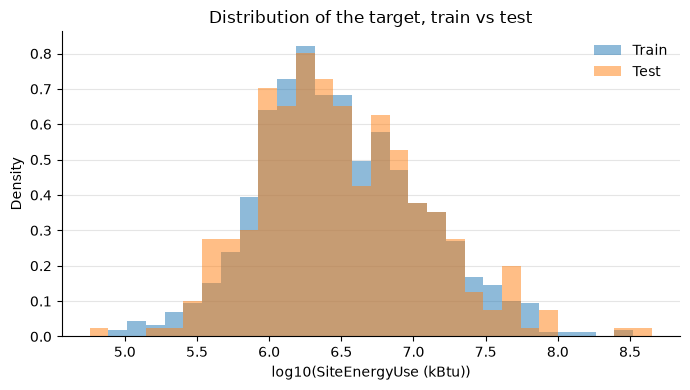

,Train,Test
count,1228.000,307.000
mean,6.492,6.498
std,0.564,0.577
min,4.902,4.757
25%,6.101,6.087
50%,6.437,6.429
75%,6.861,6.872
max,8.467,8.652


In [3]:
# Check: log10(y) distributions of the two sets (for display only)
log_train, log_test = np.log10(y_train), np.log10(y_test)
log_all = np.log10(y)

fig, ax = plt.subplots(figsize=(7, 4))

bins = np.linspace(log_all.min(), log_all.max(), 31)
ax.hist(log_train, bins=bins, density=True, alpha=0.5, label="Train")
ax.hist(log_test, bins=bins, density=True, alpha=0.5, label="Test")
ax.set_xlabel("log10(SiteEnergyUse (kBtu))")
ax.set_ylabel("Density")
ax.set_title("Distribution of the target, train vs test")
ax.legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame({"Train": log_train.describe(), "Test": log_test.describe()})
display(summary.round(3))

In [4]:
counts = (
    pd.DataFrame(
        {
            "Train": X_train["PrimaryPropertyType"].value_counts(),
            "Test": X_test["PrimaryPropertyType"].value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
)
counts["Test share"] = (counts["Test"] / (counts["Train"] + counts["Test"])).round(3)
counts.sort_values("Train", ascending=False)

,Train,Test,Test share
PrimaryPropertyType,,,
Small- and Mid-Sized Office,226,60,0.210
Other,197,48,0.196
Warehouse,147,38,0.205
Large Office,131,38,0.225
Mixed Use Property,80,24,0.231
Retail Store,73,12,0.141
Hotel,57,18,0.240
Worship Facility,56,13,0.188
Distribution Center,49,4,0.075


The two sets have almost the same distribution of the target.

Most property types have about 20% of their properties in the test set. By chance, no hospital is in the test set. We keep the split as is: changing the random seed to fix it would mean choosing the test set after looking at it. The cross-validation still evaluates the models on hospitals.

## 2. Checks on the training set

This section uses `X_train` only. It keeps the checks that drive a preprocessing choice.

### Rare property types

Laboratories and hospitals have only about 10 properties each in the training set. They are also among the most energy-intensive types (notebook 01). Grouping rare categories at encoding time would merge them and lose this signal. We keep every type as its own category.

### Redundancy among the size variables

We look for redundant size variables with a Pearson correlation matrix.

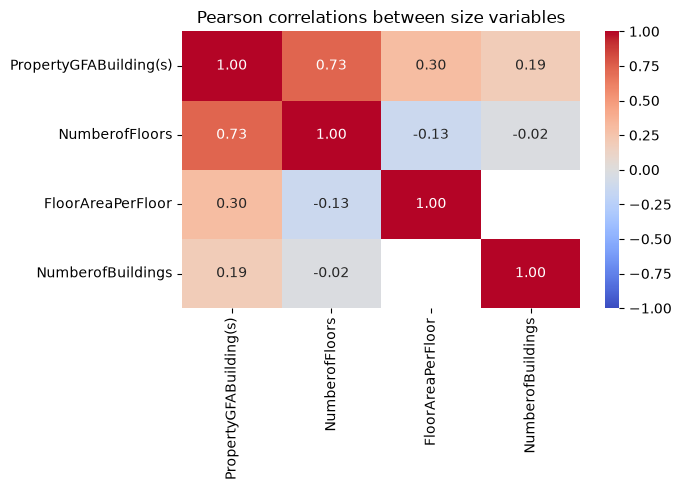

In [5]:
size_cols = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "FloorAreaPerFloor",
    "NumberofBuildings",
]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    X_train[size_cols].corr(),
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    ax=ax,
)
ax.grid(False)
ax.set_title("Pearson correlations between size variables")
plt.tight_layout()
plt.show()

The area and the number of floors are strongly correlated (0.73). The other pairs are weak. No pair is close to 1, so the matrix alone does not justify dropping a variable.

But by construction, area = floors × area per floor: any of the three follows from the other two. The linear model therefore gets only two of them. The tree-based models keep all three.

`FloorAreaPerFloor` is missing for all campuses, hence the empty cell. Its missing values carry information, so the imputation adds an indicator column.

## 3. Preprocessing

We build one preprocessor per model family. Each one is the first step of a pipeline, so that imputation, scaling and encoding are fitted on the training folds only.

| | Linear model (Ridge) | Tree-based models (random forest, CatBoost) |
|---|---|---|
| Skewed sizes (area, floors, number of buildings) | log10 | as is |
| Size variables | area and floors | area, floors and `FloorAreaPerFloor` |
| Scaling | `StandardScaler`, needed for the regularization | none |
| Categories | one-hot | one-hot (random forest), native (CatBoost) |

All three impute the missing values with the median and add a missing indicator. The binary columns are never scaled, and a category unseen in training is ignored. For the linear model, we drop `FloorAreaPerFloor` rather than `NumberofFloors`: it has more missing values, and it has no physical meaning for a campus.

In [6]:
X_train.isna().sum()

PropertyGFABuilding(s)     0
PrimaryPropertyType        0
NumberofFloors            11
NumberofBuildings          0
Neighborhood               0
Latitude                   0
Longitude                  0
ParkingShare               0
HasMixedUsage              0
ConstructionPeriod         0
FloorAreaPerFloor         51
dtype: int64

In [7]:
CATEGORICAL = ["PrimaryPropertyType", "Neighborhood", "ConstructionPeriod"]
LOG_COLS = ["PropertyGFABuilding(s)", "NumberofFloors", "NumberofBuildings"]
PLAIN_NUMERIC_COLS = [
    "ParkingShare",
    "Latitude",
    "Longitude",
]  # no log; scaled for the linear models only
BINARY_COLS = ["HasMixedUsage"]  # already 0/1, never scaled
TREE_ONLY_COLS = [
    "FloorAreaPerFloor"
]  # redundant with the two size variables for a linear model


def make_one_hot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def make_imputer(add_indicator):
    return SimpleImputer(strategy="median", add_indicator=add_indicator)


def make_linear_preprocessor():
    """Log of the skewed sizes, scaling, imputation, one-hot encoding.

    The missing indicator is generated by its own step, outside of the sub-pipeline,
    so that it is not scaled.
    """
    log_pipeline = make_pipeline(
        FunctionTransformer(np.log10, feature_names_out="one-to-one"),
        StandardScaler(),
        make_imputer(add_indicator=False),
    )
    return ColumnTransformer(
        [
            ("log", log_pipeline, LOG_COLS),
            ("missing", MissingIndicator(features="missing-only"), ["NumberofFloors"]),
            ("plain_numeric", StandardScaler(), PLAIN_NUMERIC_COLS),
            ("binary", "passthrough", BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        remainder="drop",  # FloorAreaPerFloor
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def make_tree_preprocessor():
    """No transformation of the values: imputation (with indicator) and one-hot encoding."""
    return ColumnTransformer(
        [
            ("num", make_imputer(add_indicator=True), LOG_COLS + TREE_ONLY_COLS),
            ("plain", "passthrough", PLAIN_NUMERIC_COLS + BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def make_catboost_preprocessor():
    """No transformation of the values: imputation (with indicator).

    Categories are encoded by CatBoost itself (ordered target statistics) via cat_features.
    """
    return ColumnTransformer(
        [
            ("num", make_imputer(add_indicator=True), LOG_COLS + TREE_ONLY_COLS),
            ("plain", "passthrough", PLAIN_NUMERIC_COLS + BINARY_COLS),
            ("cat", "passthrough", CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

### Check

We fit each preprocessor on the training set and check its output: no missing value, and centered numeric columns for the linear model.

In [8]:
for name, make in [
    ("Linear", make_linear_preprocessor),
    ("Trees", make_tree_preprocessor),
    ("CatBoost", make_catboost_preprocessor),
]:
    prep = make().fit(X_train)
    out_train, out_test = prep.transform(X_train), prep.transform(X_test)
    assert not out_train.isna().any().any() and not out_test.isna().any().any()
    print(f"{name}: {X_train.shape[1]} -> {out_train.shape[1]} columns")
    indicators = [c for c in out_train.columns if c.startswith("missingindicator")]
    print(f"  missing indicators: {indicators}")

linear_out = make_linear_preprocessor().fit_transform(X_train)
linear_out.iloc[:, :6].astype(float).describe().loc[
    ["mean", "std", "min", "max"]
].round(2)

Linear: 11 -> 46 columns
  missing indicators: ['missingindicator_NumberofFloors']
Trees: 11 -> 48 columns
  missing indicators: ['missingindicator_NumberofFloors', 'missingindicator_FloorAreaPerFloor']
CatBoost: 11 -> 13 columns
  missing indicators: ['missingindicator_NumberofFloors', 'missingindicator_FloorAreaPerFloor']


,PropertyGFABuilding(s),NumberofFloors,NumberofBuildings,missingindicator_NumberofFloors,ParkingShare,Latitude
mean,0.00,-0.00,-0.00,0.01,0.00,0.00
std,1.00,1.00,1.00,0.09,1.00,1.00
min,-1.82,-1.14,-0.17,0.00,-0.45,-2.26
max,3.77,3.90,11.81,1.00,5.10,2.48


## 4. Evaluation protocol

| Element | Choice |
|---|---|
| Cross-validation | 5 folds, stratified on the deciles of `y_train`, shared by all the models |
| Decision metric | MAPE, the mean absolute percentage error. Each property weighs the same, whatever its size |
| Other metrics | R², MAE and RMSE, in kBtu. The largest properties dominate them |
| Overfitting signal | Gap between the train and validation scores |
| Baselines | A dummy model and a business rule, the reference to beat |

The MAPE has a known bias: it penalizes overestimates more than underestimates. A prediction can be 200% too high, but at most 100% too low.

`evaluate_model` cross-validates a model and returns its train and validation scores. `results_table` displays them.

In [9]:
def evaluate_model(
    model: Any,
    X: pd.DataFrame,
    y: pd.Series,
    cv: list[tuple[np.ndarray, np.ndarray]],
    scorers: dict[str, str | Callable],
    model_name: str,
) -> dict[str, Any]:
    """Cross-validate a model on explicit folds and return one row of the summary table.

    Train and validation scores are averaged over the folds (mean and std). Keys starting
    with 'neg_' are errors: the sign is flipped back and the prefix removed. The gap is
    positive when the model does worse on validation (val - train for errors, train - val otherwise).
    """
    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scorers,
        return_train_score=True,
    )

    row: dict[str, Any] = {
        "model": model_name,
        "fit_time_mean": results["fit_time"].mean(),
    }
    for key in scorers:
        is_error = key.startswith("neg_")
        name = key.removeprefix("neg_")
        sign = -1 if is_error else 1  # scikit-learn negates errors: flip them back

        train = sign * results[f"train_{key}"]
        val = sign * results[f"test_{key}"]

        row[f"{name}_train_mean"] = train.mean()
        row[f"{name}_train_std"] = train.std()
        row[f"{name}_val_mean"] = val.mean()
        row[f"{name}_val_std"] = val.std()
        row[f"{name}_gap"] = (
            val.mean() - train.mean() if is_error else train.mean() - val.mean()
        )
    return row


def with_log_target(regressor: Any) -> TransformedTargetRegressor:
    """Wrap a regressor so that it learns log10(y) and predicts in kBtu."""
    return TransformedTargetRegressor(
        regressor=regressor, func=np.log10, inverse_func=partial(np.power, 10.0)
    )


METRICS = {
    "MAPE": "mean_absolute_percentage_error",
    "R2": "r2",
    "MAE (kBtu)": "mean_absolute_error",
    "RMSE (kBtu)": "root_mean_squared_error",
}


def results_table(results: pd.DataFrame) -> Styler:
    """Train and validation scores of each metric (mean over the folds), and the fit time.

    Two-level header: the metric, then train / validation. The standard deviation of the
    validation MAPE across the folds is the noise margin used to compare the models.
    The best validation MAPE is in bold. A vertical line separates the metrics.
    """
    columns = {}
    for label, name in METRICS.items():
        columns[(label, "train")] = results[f"{name}_train_mean"]
        columns[(label, "validation")] = results[f"{name}_val_mean"]
        if label == "MAPE":
            columns[(label, "validation std")] = results[f"{name}_val_std"]
    columns[("Fit time (s)", "")] = results["fit_time_mean"]
    table = pd.DataFrame(columns).rename_axis(index=None)

    # First column of each metric: vertical separator on its left
    metrics = table.columns.get_level_values(0)
    group_starts = [
        col
        for i, col in enumerate(table.columns)
        if i == 0 or metrics[i] != metrics[i - 1]
    ]
    separators = {
        col: [{"selector": "th, td", "props": "border-left: 1px solid #999"}]
        for col in group_starts
    }
    return (
        styled(table)
        .highlight_min(subset=[("MAPE", "validation")], props="font-weight: bold")
        .set_table_styles(
            [
                {"selector": "th.col_heading", "props": "text-align: center"},
                {"selector": "td", "props": "text-align: right; padding: 0 8px"},
            ]
        )
        .set_table_styles(separators, overwrite=False)
    )

The folds are built once, so that every model is evaluated on the same properties.

In [10]:
y_train_bins = pd.qcut(y_train, q=10, labels=False)

cv = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(
        X_train, y_train_bins
    )
)

for i, (train_idx, val_idx) in enumerate(cv, start=1):
    print(f"Fold {i}: train {len(train_idx)} rows | validation {len(val_idx)} rows")
assert sorted(np.concatenate([val for _, val in cv])) == list(range(len(X_train)))

Fold 1: train 982 rows | validation 246 rows
Fold 2: train 982 rows | validation 246 rows
Fold 3: train 982 rows | validation 246 rows
Fold 4: train 983 rows | validation 245 rows
Fold 5: train 983 rows | validation 245 rows


In [11]:
# Regression metrics; errors are negated by scikit-learn ("neg_" prefix)
scorers = {
    "neg_mean_absolute_percentage_error": "neg_mean_absolute_percentage_error",
    "r2": "r2",
    "neg_mean_absolute_error": "neg_mean_absolute_error",
    "neg_root_mean_squared_error": "neg_root_mean_squared_error",
}
DECISION_SCORER = "neg_mean_absolute_percentage_error"

### Baselines

- The dummy model predicts the same value for every property, the typical energy use of the training set. Every model must beat it by far.
- The business rule multiplies the building area by the median EUI of its type, learned on the training folds. It is what the city could compute without machine learning, like a taxi fare estimated as distance × price per mile. It is the reference to beat.

In [12]:
class TypeIntensityBaseline(RegressorMixin, BaseEstimator):
    """Business rule: building area x median intensity of the property type, in kBtu.

    The median log10 intensity of each type is learned on the training data; a type
    unseen during fit gets the overall median.
    """

    def fit(self, X, y):
        log_intensity = np.log10(y / X["PropertyGFABuilding(s)"])
        self.medians_ = log_intensity.groupby(X["PrimaryPropertyType"]).median()
        self.global_median_ = log_intensity.median()
        return self

    def predict(self, X):
        log_intensity = (
            X["PrimaryPropertyType"]
            .map(self.medians_)
            .astype(float)
            .fillna(self.global_median_)
        )
        return (10**log_intensity * X["PropertyGFABuilding(s)"]).to_numpy()


baselines = {
    "Dummy (mean of log10)": with_log_target(DummyRegressor(strategy="mean")),
    "Business rule (area x type)": TypeIntensityBaseline(),
}
baseline_rows = [
    evaluate_model(model, X_train, y_train, cv, scorers, name)
    for name, model in baselines.items()
]

## 5. Model comparison

Three models from three families, with their default settings, on the same folds:

- Ridge, a linear regression with L2 regularization.
- Random forest, a bagging of decision trees.
- CatBoost, a gradient boosting of decision trees, with native handling of the categories.

In [13]:
models = {
    "Ridge (alpha=1)": with_log_target(
        make_pipeline(make_linear_preprocessor(), Ridge())
    ),
    "Random forest (default)": with_log_target(
        make_pipeline(
            make_tree_preprocessor(), RandomForestRegressor(random_state=RANDOM_STATE)
        )
    ),
    "CatBoost (default)": with_log_target(
        make_pipeline(
            make_catboost_preprocessor(),
            CatBoostRegressor(
                random_state=RANDOM_STATE,
                verbose=0,
                allow_writing_files=False,
                cat_features=tuple(CATEGORICAL),
            ),
        )
    ),
}

rows = baseline_rows + [
    evaluate_model(model, X_train, y_train, cv, scorers, name)
    for name, model in models.items()
]
results = pd.DataFrame(rows).set_index("model")
results_table(results)

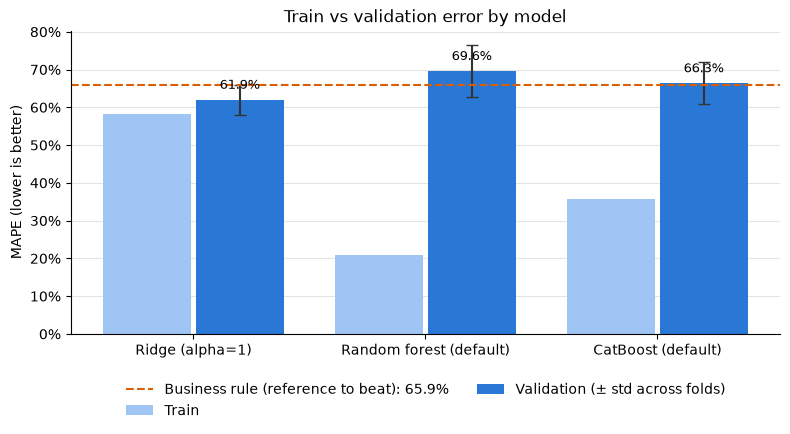

In [14]:
# Train vs validation MAPE of the three models, business rule as reference line
compared = results.drop(index=list(baselines))
x = np.arange(len(compared))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    x - width / 2 - 0.01,
    compared["mean_absolute_percentage_error_train_mean"],
    width,
    color="#9ec5f4",
    label="Train",
)
ax.bar(
    x + width / 2 + 0.01,
    compared["mean_absolute_percentage_error_val_mean"],
    width,
    yerr=compared["mean_absolute_percentage_error_val_std"],
    capsize=4,
    color="#2a78d6",
    ecolor="#333333",
    label="Validation (± std across folds)",
)
for xi, value in zip(x, compared["mean_absolute_percentage_error_val_mean"]):
    ax.annotate(
        FORMATS["MAPE"].format(value),
        (xi + width / 2 + 0.01, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

rule_mape = results.loc[
    "Business rule (area x type)", "mean_absolute_percentage_error_val_mean"
]
ax.axhline(
    rule_mape,
    color="#d95f02",
    linestyle="--",
    linewidth=1.5,
    label=f"Business rule (reference to beat): {FORMATS['MAPE'].format(rule_mape)}",
)

ax.set_xticks(x, compared.index)
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_ylabel("MAPE (lower is better)")
ax.set_title("Train vs validation error by model")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout()
plt.show()

- Every model beats the dummy model by far, but no model clearly beats the business rule. Ridge has the lowest validation MAPE (62% against 66% for the rule).
- The tree-based models overfit with their default settings. The random forest goes from 21% on the training folds to 70% on validation, and its R² drops from 0.94 to 0.73. Ridge barely overfits (58% vs 62%).
- In R², the rule is even slightly better (0.77 against about 0.72).
- Three very different model families stop at the level of a rule that only uses the area and the type. The limit seems to be in the information the features carry, not in the models.

A MAPE around 60% looks high. Small properties whose energy use is overestimated pull it up: an overestimate has no upper bound.

## 6. Hyperparameter optimization

We tune CatBoost with a grid search, on the same folds and with the same metrics. Ridge is about as good, but it has a single hyperparameter and almost no overfitting to reduce. CatBoost has many hyperparameters and overfits with its default settings, so it has the most to gain.

The grid covers the default values of CatBoost, with smaller and larger values around them.

| Hyperparameter | Values |
|---|---|
| `depth` | 4, 5, 6 |
| `l2_leaf_reg` | 1, 3, 10, 30 |
| `learning_rate` | 0.03, 0.05, 0.1 |
| `iterations` | 600, 1000, 1500 |

That is 108 combinations, each cross-validated on 5 folds: 540 fits. This number grows fast with each hyperparameter, so we keep the grid small.

The tuned model succeeds if it beats the business rule by more than the variation between folds.

In [15]:
# Names: regressor__ (inside TransformedTargetRegressor), then catboostregressor__ (pipeline step)
param_grid = {
    "regressor__catboostregressor__depth": [4, 5, 6],
    "regressor__catboostregressor__l2_leaf_reg": [1, 3, 10, 30],
    "regressor__catboostregressor__learning_rate": [0.03, 0.05, 0.1],
    "regressor__catboostregressor__iterations": [600, 1000, 1500],
}

grid = GridSearchCV(
    clone(models["CatBoost (default)"]),
    param_grid,
    cv=cv,
    scoring=scorers,
    refit=DECISION_SCORER,
    return_train_score=True,
    verbose=1,
)
grid.fit(X_train, y_train)

best_params = {k.split("__")[-1]: v for k, v in grid.best_params_.items()}
print(f"Best parameters: {best_params}")
print(f"Best validation MAPE: {FORMATS['MAPE'].format(-grid.best_score_)}")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'depth': 5, 'iterations': 600, 'l2_leaf_reg': 10, 'learning_rate': 0.05}
Best validation MAPE: 64.7%


In [16]:
# The tuned model in the same table as the comparison (same folds, same scorers)
tuned_row = evaluate_model(
    grid.best_estimator_, X_train, y_train, cv, scorers, "CatBoost (tuned)"
)
results_tuned = pd.concat([results, pd.DataFrame([tuned_row]).set_index("model")])
results_table(results_tuned)

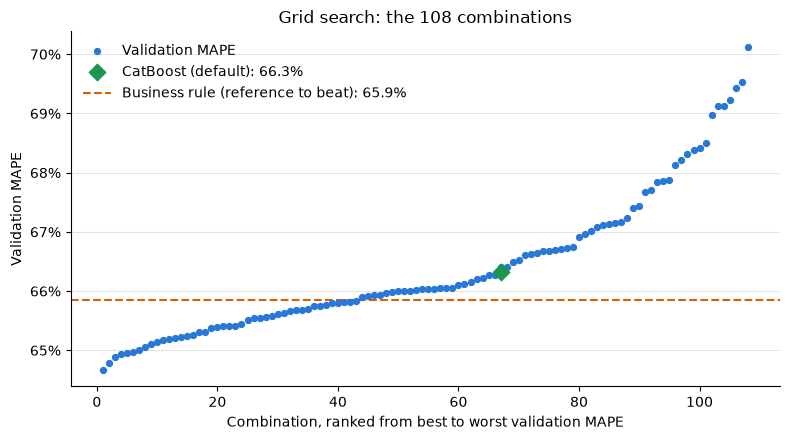

In [17]:
# The 108 combinations ranked from best to worst validation MAPE
search = pd.DataFrame(grid.cv_results_)
val_mape = -search["mean_test_neg_mean_absolute_percentage_error"].sort_values(
    ascending=False
)
rank = np.arange(1, len(val_mape) + 1)

rule_mape = results.loc[
    "Business rule (area x type)", "mean_absolute_percentage_error_val_mean"
]
default_mape = results.loc[
    "CatBoost (default)", "mean_absolute_percentage_error_val_mean"
]
default_rank = 1 + (val_mape < default_mape).sum()  # where the default would be ranked

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(rank, val_mape, s=18, color="#2a78d6", label="Validation MAPE", zorder=3)
ax.scatter(
    default_rank,
    default_mape,
    s=70,
    marker="D",
    color="#1a9850",
    label=f"CatBoost (default): {FORMATS['MAPE'].format(default_mape)}",
    zorder=4,
)
ax.axhline(
    rule_mape,
    color="#d95f02",
    linestyle="--",
    linewidth=1.5,
    label=f"Business rule (reference to beat): {FORMATS['MAPE'].format(rule_mape)}",
)
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_xlabel("Combination, ranked from best to worst validation MAPE")
ax.set_ylabel("Validation MAPE")
ax.set_title("Grid search: the 108 combinations")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

Tuning mostly reduces the overfitting. The train MAPE goes from 36% to 48%, closer to validation, while the validation MAPE barely moves (from 66% to 65%).

All 108 combinations fall within about 5 points of validation MAPE, the same order as the variation between folds: the search reaches a plateau. The default setting sits in the middle, and no setting beats the business rule by more than this variation.

The success criterion is not met. The tuned CatBoost is level with the business rule and does not beat Ridge.

### Fold-by-fold comparison

All the models are evaluated on the same 5 folds, so we can compare them fold by fold (a paired comparison). The folds are not equally hard: fold 4 is the easiest one for the rule (56%) and for Ridge (55%). The spread of each model across the folds therefore overstates the noise of a comparison between two models. The right measure is the spread of the gain, fold by fold.

In [18]:
# Validation MAPE of each model on each of the 5 shared folds
fold_models = {
    "Business rule (area x type)": baselines["Business rule (area x type)"],
    **models,
    "CatBoost (tuned)": grid.best_estimator_,
}
fold_mape = pd.DataFrame(
    {
        name: -cross_validate(model, X_train, y_train, cv=cv, scoring=DECISION_SCORER)[
            "test_score"
        ]
        for name, model in fold_models.items()
    },
    index=pd.RangeIndex(1, len(cv) + 1, name="Fold"),
)

# Check: the means match the comparison table
assert np.allclose(
    fold_mape.mean(),
    results_tuned.loc[fold_mape.columns, "mean_absolute_percentage_error_val_mean"],
)


def paired_comparison(reference: str, challenger: str) -> dict[str, Any]:
    """Compare two models on the same folds.

    A positive gain means that the challenger does better than the reference.
    """
    gain = 100 * (fold_mape[reference] - fold_mape[challenger])  # in MAPE points
    return {
        "Reference": reference,
        "Challenger": challenger,
        "Folds won": f"{(gain > 0).sum()} / {len(gain)}",
        "Mean gain (points)": gain.mean(),
        "Std of the gain (points)": gain.std(),
    }


rule = "Business rule (area x type)"
pairs = [(rule, name) for name in [*models, "CatBoost (tuned)"]] + [
    ("CatBoost (default)", "CatBoost (tuned)")
]
comparison = pd.DataFrame([paired_comparison(ref, chal) for ref, chal in pairs])

display(fold_mape.style.format("{:.1%}"))
display(
    comparison.style.format(
        {"Mean gain (points)": "{:+.1f}", "Std of the gain (points)": "{:.1f}"}
    ).hide(axis="index")
)

,Business rule (area x type),Ridge (alpha=1),Random forest (default),CatBoost (default),CatBoost (tuned)
Fold,,,,,
1,65.1%,62.0%,63.9%,62.8%,63.0%
2,70.1%,66.7%,82.5%,76.8%,75.1%
3,68.7%,61.5%,66.8%,62.2%,61.5%
4,56.3%,54.9%,64.0%,62.5%,57.9%
5,69.1%,64.6%,70.7%,67.4%,65.8%


Reference,Challenger,Folds won,Mean gain (points),Std of the gain (points)
Business rule (area x type),Ridge (alpha=1),5 / 5,+3.9,2.1
Business rule (area x type),Random forest (default),2 / 5,-3.7,6.2
Business rule (area x type),CatBoost (default),3 / 5,-0.5,5.7
Business rule (area x type),CatBoost (tuned),3 / 5,+1.2,4.7
CatBoost (default),CatBoost (tuned),4 / 5,+1.7,1.8


- Ridge beats the business rule on all 5 folds, by 3.9 points on average. The gain is small but steady: its standard deviation (2.1 points) is about half the spread of each model across the folds.
- The other models do not beat the rule steadily. The random forest wins 2 folds out of 5, CatBoost 3 out of 5 with or without tuning, and their gains vary much more (standard deviation of 4.7 to 6.2 points).
- Tuning improves CatBoost on 4 folds out of 5, by 1.7 points on average. This gain is optimistic: the best of 108 combinations was selected on these same folds.

## 7. Final evaluation on the test set

### Decision

We select Ridge, before looking at the test set. It has the lowest validation MAPE, but within the variation between folds of the rule and the tuned CatBoost. Among models this close, we take the simplest: Ridge is the fastest to fit, it barely overfits, and its coefficients can be read.

The business rule remains the benchmark: a model is only worth deploying if it does better. The test set checks the choice, it does not make it.

### Test-set scores

We fit the dummy model, the business rule and Ridge on the whole training set. The grid search already refitted the tuned CatBoost. All four are evaluated once on the test set. The second table compares the cross-validation and test scores.

In [19]:
final_models = {
    "Dummy (mean of log10)": clone(baselines["Dummy (mean of log10)"]),
    "Business rule (area x type)": clone(baselines["Business rule (area x type)"]),
    "Ridge (alpha=1)": clone(models["Ridge (alpha=1)"]),
}
for model in final_models.values():
    model.fit(X_train, y_train)
final_models["CatBoost (tuned)"] = grid.best_estimator_  # already refitted on X_train


def test_scores(model: Any, X: pd.DataFrame, y: pd.Series) -> dict[str, float]:
    """Score a fitted model with the scorers of the cross-validation (errors in positive)."""
    row = {}
    for key, scorer in scorers.items():
        scorer = get_scorer(scorer) if isinstance(scorer, str) else scorer
        sign = -1 if key.startswith("neg_") else 1
        row[key.removeprefix("neg_")] = sign * scorer(model, X, y)
    return row


test_results = pd.DataFrame(
    {name: test_scores(model, X_test, y_test) for name, model in final_models.items()}
).T

test_table = pd.DataFrame(
    {label: test_results[name] for label, name in METRICS.items()}
)
display(styled(test_table).highlight_min(subset=["MAPE"], props="font-weight: bold"))

# Cross-validation (training set) vs test
cv_vs_test = pd.DataFrame(
    {
        "MAPE (CV)": results_tuned["mean_absolute_percentage_error_val_mean"],
        "MAPE (test)": test_table["MAPE"],
        "R2 (CV)": results_tuned["r2_val_mean"],
        "R2 (test)": test_table["R2"],
    }
).loc[list(final_models)]
styled(cv_vs_test)

,MAPE,R2,MAE (kBtu),RMSE (kBtu)
Dummy (mean of log10),164.8%,-0.040,"8,167,503","32,430,606"
Business rule (area x type),66.6%,0.193,"5,544,747","28,571,714"
Ridge (alpha=1),63.6%,0.215,"5,422,120","28,175,284"
CatBoost (tuned),61.1%,0.191,"5,289,582","28,609,972"


,MAPE (CV),MAPE (test),R2 (CV),R2 (test)
Dummy (mean of log10),164.7%,164.8%,-0.073,-0.040
Business rule (area x type),65.9%,66.6%,0.769,0.193
Ridge (alpha=1),61.9%,63.6%,0.723,0.215
CatBoost (tuned),64.7%,61.1%,0.723,0.191


In MAPE, the test confirms the cross-validation. The three candidates stay close to each other and to their cross-validation scores. CatBoost does slightly better than Ridge on the test set, but by less than the variation between folds, so we keep Ridge.

The R² collapses for every model, from about 0.75 in cross-validation to about 0.2. The problem is in the test set, not in one model. The next subsections explain why.

### Predicted vs actual

One panel per candidate, on log10 scales so that small and large properties are equally visible. The line is a perfect prediction. The circled point is the largest consumer of the test set.

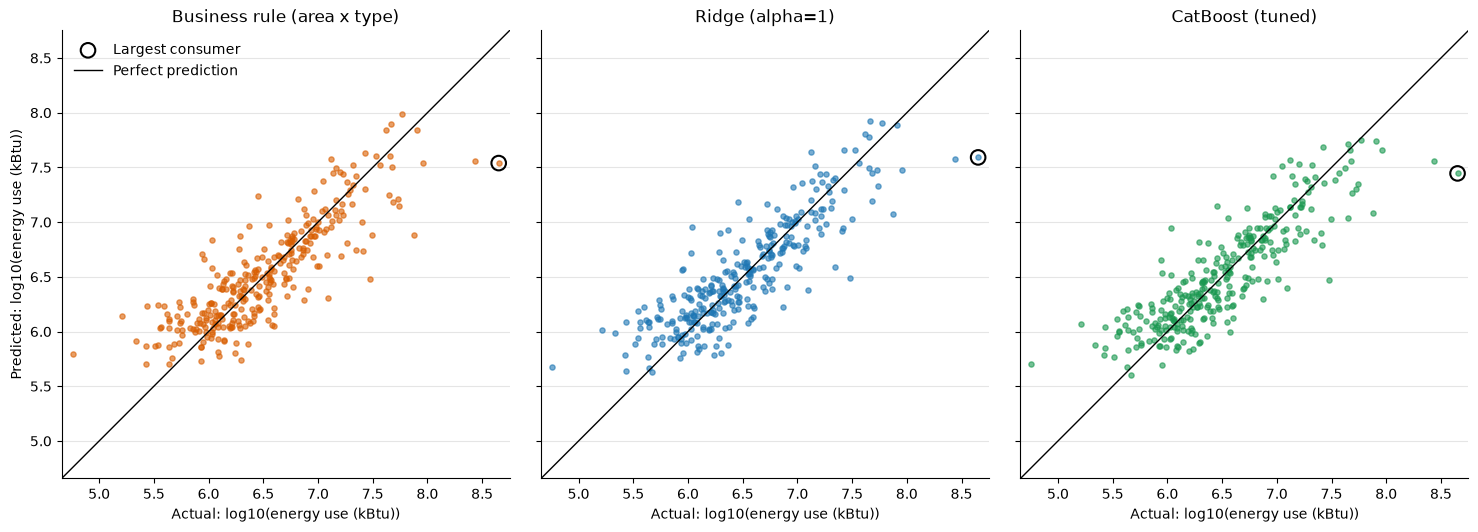

In [20]:
candidates = {
    "Business rule (area x type)": "#d95f02",
    "Ridge (alpha=1)": "#1f77b4",
    "CatBoost (tuned)": "#1a9850",
}
test_pred = {
    name: pd.Series(final_models[name].predict(X_test), index=y_test.index)
    for name in candidates
}

log_actual = np.log10(y_test)
largest = y_test.idxmax()
lo = min(log_actual.min(), *(np.log10(p).min() for p in test_pred.values())) - 0.1
hi = max(log_actual.max(), *(np.log10(p).max() for p in test_pred.values())) + 0.1

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, (name, color) in zip(axes, candidates.items()):
    log_pred = np.log10(test_pred[name])
    ax.scatter(log_actual, log_pred, s=14, alpha=0.6, color=color)
    ax.scatter(
        log_actual[largest],
        log_pred[largest],
        s=110,
        facecolors="none",
        edgecolors="k",
        linewidths=1.5,
        label="Largest consumer",
    )
    ax.plot([lo, hi], [lo, hi], "k-", linewidth=1, label="Perfect prediction")
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect("equal")
    ax.set_title(name)
    ax.set_xlabel("Actual: log10(energy use (kBtu))")
axes[0].set_ylabel("Predicted: log10(energy use (kBtu))")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

For the three candidates, most points follow the diagonal. A few properties lie far below it: the models strongly underestimate them.

### Largest errors

The five properties with the largest errors of Ridge, in kBtu.

In [21]:
ridge_pred = test_pred["Ridge (alpha=1)"]
abs_error = (ridge_pred - y_test).abs().sort_values(ascending=False)
worst = abs_error.head(5).index

# Energy use per sq ft; the median of each type is computed on the training set
area = X_test.loc[worst, "PropertyGFABuilding(s)"]
type_median_intensity = (
    (y_train / X_train["PropertyGFABuilding(s)"])
    .groupby(X_train["PrimaryPropertyType"])
    .median()
)
worst_types = X_test.loc[worst, "PrimaryPropertyType"]

worst_table = pd.DataFrame(
    {
        "Type": worst_types,
        "Actual": y_test[worst],
        "Predicted": ridge_pred[worst],
        "Predicted/Actual ratio": ridge_pred[worst] / y_test[worst],
        "Actual intensity (kBtu/sq ft)": y_test[worst] / area,
        "Median intensity of the type (kBtu/sq ft)": worst_types.map(
            type_median_intensity
        ),
    }
).reset_index(drop=True)
display(styled(worst_table))

# Share of the total squared error carried by the k largest errors
squared_error = abs_error**2
cumulative_share = pd.DataFrame(
    [[squared_error.iloc[:k].sum() / squared_error.sum() for k in (1, 3, 5, 10)]],
    columns=[f"k = {k}" for k in (1, 3, 5, 10)],
    index=["Share of the total squared error"],
)
cumulative_share.style.format("{:.0%}")

,Type,Actual,Predicted,Predicted/Actual ratio,Actual intensity (kBtu/sq ft),Median intensity of the type (kBtu/sq ft)
0,Mixed Use Property,"448,385,312","39,041,655",0.09,906,70
1,Other,"274,682,208","37,351,798",0.14,640,83
2,Mixed Use Property,"75,073,888","11,830,214",0.16,689,70
3,University,"90,609,640","30,116,819",0.33,169,64
4,Other,"46,510,960","84,012,098",1.81,49,83


,k = 1,k = 3,k = 5,k = 10
Share of the total squared error,69%,94%,96%,97%


### The three largest errors in the raw data

The processed files have no property ID, so we found the three properties in the raw file by matching their energy use and coordinates.

| Property (ID) | Building type | Primary type (used by the models) | Actual energy use | All use types |
|---|---|---|---|---|
| Plant 2 Site (43) | Campus | Mixed Use Property | 448 M kBtu | Energy/Power Station, Laboratory, Manufacturing/Industrial Plant, Non-Refrigerated Warehouse, Office |
| WestinBuilding (753) | NonResidential | Other | 275 M kBtu | Data Center, Office |
| Fisher Plaza - West Building (440) | NonResidential | Mixed Use Property | 75 M kBtu | Data Center, Financial Office, Office, Other, Parking, Restaurant |

The three largest errors are underestimates by a factor of 6 to 11. The models see these properties as "Mixed Use Property" or "Other". Yet their list of use types contains very energy-intensive uses: a power station, laboratories and a factory, or a data center. Their EUI is 8 to 13 times the median of their type.

This information is in `ListOfAllPropertyUseTypes`, but no feature uses it. A flag for energy-intensive uses, built from this list, would let the models see these properties.

These 3 properties out of 307 carry 94% of the squared error of Ridge. The R² and the RMSE square the errors, so these few properties drive them. The MAPE gives the same weight to every property, so it is much less affected.

## 8. Feature importance

Ridge is not a tree-based model, so we use the permutation importance. Each feature is shuffled in turn on the test set, and its importance is the increase of the MAPE it causes. A feature matters if the model does worse without its information.

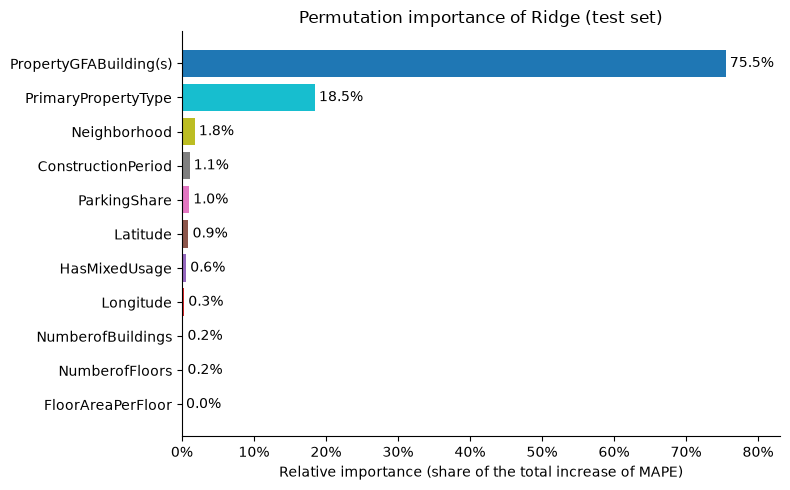

In [22]:
perm = permutation_importance(
    final_models["Ridge (alpha=1)"],
    X_test,
    y_test,
    scoring=DECISION_SCORER,
    n_repeats=30,
    random_state=RANDOM_STATE,
)
importance = pd.Series(perm.importances_mean, index=X_test.columns)
relative_importance = (importance / importance.sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = sns.color_palette("tab10", len(relative_importance))
bars = ax.barh(relative_importance.index, relative_importance, color=colors)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in relative_importance], padding=3)
ax.margins(x=0.1)
ax.xaxis.set_major_formatter("{x:.0%}")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Relative importance (share of the total increase of MAPE)")
ax.set_title("Permutation importance of Ridge (test set)")
plt.tight_layout()
plt.show()

The building area comes first and the property type second. Together, they carry more than 90% of the importance. Ridge relies on the same two signals as the business rule, which explains why it does not do much better. The other features add little. `FloorAreaPerFloor` has no importance because the linear model does not use it.

## 9. Summary

We wanted to predict the energy use of a non-residential property in Seattle from its structural characteristics alone: area, type, floors, location, construction period.

No model, even tuned, does clearly better than a simple business rule: the building area times the median EUI of its type. This holds in cross-validation and on the test set.

We select Ridge. It is as good as the more complex models, and it is the simplest, the fastest to fit and the easiest to read. Like the rule, it relies mostly on the area and the type.

The R² and the RMSE of the test set are driven by three properties with energy-intensive uses (a power station, data centers) that the features do not describe. The MAPE is the metric to trust here.

The next step is to improve the features rather than the model. A flag for energy-intensive uses, built from the list of use types, would let the models see these properties. A specific treatment of campuses would also help.